In [44]:
%pip install seaborn

  Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl.metadata (19 kB)
Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl (9.7 MB)

   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ---------

In [25]:
from transliterate import translit
import os

def transliterate_surnames(latin_name):
    return translit(latin_name, reversed=True, language_code="ru")

dictionary_names = {}
for file_names in os.listdir("data/names/"):
    with open(f"data/names/{file_names}","r", encoding="utf-8") as txt_file_name:
        for dict_key in txt_file_name:
            nationality = file_names[:-4]
            latin_name = dict_key.strip()
            name_cyr = transliterate_surnames(latin_name)
            dictionary_names[name_cyr] = nationality
print(dictionary_names)

{'Khoury': 'Arabic', 'Nahas': 'Arabic', 'Daher': 'Arabic', 'Gerges': 'Arabic', 'Nazari': 'Arabic', 'Maalouf': 'Arabic', 'Naifeh': 'Arabic', 'Guirguis': 'Arabic', 'Baba': 'Japanese', 'Sabbagh': 'Arabic', 'Attia': 'Arabic', 'Tahan': 'Arabic', 'Haddad': 'Arabic', 'Aswad': 'Arabic', 'Najjar': 'Arabic', 'Dagher': 'Arabic', 'Maloof': 'Arabic', 'Isa': 'Arabic', 'Asghar': 'Arabic', 'Nader': 'Arabic', 'Gaber': 'Arabic', 'Abboud': 'Arabic', 'Zogby': 'Arabic', 'Srour': 'Arabic', 'Bahar': 'Arabic', 'Mustafa': 'English', 'Hanania': 'Arabic', 'Tuma': 'Arabic', 'Saliba': 'Arabic', 'Shamoon': 'Arabic', 'Handal': 'Arabic', 'Amari': 'Arabic', 'Atiyeh': 'Arabic', 'Said': 'English', 'Khouri': 'Arabic', 'Sleiman': 'Arabic', 'Seif': 'Arabic', 'Harb': 'Arabic', 'Asker': 'Arabic', 'Antar': 'Arabic', 'Awad': 'English', 'Shadid': 'Arabic', 'Hajjar': 'Arabic', 'Kalb': 'German', 'Bazzi': 'Arabic', 'Masih': 'Arabic', 'Ghanem': 'Arabic', 'Antoun': 'Arabic', 'Sarraf': 'Arabic', 'Malouf': 'Arabic', 'Naser': 'Arabic',

In [28]:
from transliterate import translit
import os
from collections import Counter
import re

def transliterate_surnames(latin_name):
    """Транслитерация фамилии с латиницы на кириллицу"""
    try:
        # Пробуем стандартную транслитерацию
        result = translit(latin_name, reversed=True, language_code="ru")
        
        # Проверяем что результат содержит кириллицу
        has_cyrillic = any(ord(c) >= 1040 and ord(c) <= 1103 for c in result)
        
        if not has_cyrillic:
            # Если нет кириллицы, пробуем альтернативный метод
            result = manual_transliteration(latin_name)
        
        return result
    except Exception as e:
        print(f"Ошибка транслитерации '{latin_name}': {e}")
        return latin_name

def manual_transliteration(text):
    """Ручная транслитерация常见ных паттернов"""
    mapping = {
        'sh': 'ш', 'ch': 'ч', 'zh': 'ж', 'kh': 'х', 'ts': 'ц',
        'ya': 'я', 'yu': 'ю', 'yo': 'ё', 'ye': 'е', 'yi': 'и',
        'a': 'а', 'b': 'б', 'v': 'в', 'g': 'г', 'd': 'д',
        'e': 'е', 'yo': 'ё', 'z': 'з', 'i': 'и', 'j': 'й',
        'k': 'к', 'l': 'л', 'm': 'м', 'n': 'н', 'o': 'о',
        'p': 'п', 'r': 'р', 's': 'с', 't': 'т', 'u': 'у',
        'f': 'ф', 'h': 'х', 'c': 'к', 'w': 'в', 'y': 'ы',
        "'": '', '`': ''
    }
    
    result = text.lower()
    # Сначала заменяем многосимвольные комбинации
    for multi, cyr in sorted(mapping.items(), key=lambda x: -len(x[0])):
        if len(multi) > 1:
            result = result.replace(multi, cyr)
    
    # Затем одиночные символы
    for single, cyr in mapping.items():
        if len(single) == 1:
            result = result.replace(single, cyr)
    
    return result

def load_and_transliterate_dataset(data_dir="data/names/", max_nationalities=10, min_samples=100):
    """Загрузка и фильтрация датасета"""
    dataset = []
    
    for file_name in os.listdir(data_dir):
        if not file_name.endswith(".txt"):
            continue
        
        file_path = os.path.join(data_dir, file_name)
        nationality = file_name[:-4]
        
        with open(file_path, "r", encoding="utf-8") as txt_file:
            for line in txt_file:
                latin_name = line.strip()
                
                if not latin_name:
                    continue
                
                name_cyr = transliterate_surnames(latin_name)
                
                if name_cyr:
                    dataset.append((name_cyr, nationality))
    
    # Фильтрация: оставляем топ-10 национальностей с минимальным порогом
    nationality_counts = Counter([item[1] for item in dataset])
    top_nationalities = [
        nat for nat, count in nationality_counts.most_common(max_nationalities)
        if count >= min_samples
    ]
    
    filtered_dataset = [
        (surname, nat) for surname, nat in dataset
        if nat in top_nationalities
    ]
    
    print(f"Исходных записей: {len(dataset)}")
    print(f"После фильтрации: {len(filtered_dataset)}")
    print(f"Национальностей: {len(top_nationalities)}")
    print(f"\nВыбранные национальности:")
    for nat in top_nationalities:
        print(f"{nat}: {nationality_counts[nat]}")
    
    return filtered_dataset, top_nationalities

# Загрузка данных
dataset, selected_nationalities = load_and_transliterate_dataset(
    data_dir="data/names/",
    max_nationalities=10,
    min_samples=100
)

# Проверка транслитерации
print("\nПримеры транслитерации:")
for surname, nationality in dataset[:10]:
    print(f"{surname} -> {nationality}")

Исходных записей: 20074
После фильтрации: 18891
Национальностей: 10

Выбранные национальности:
Russian: 9408
English: 3668
Arabic: 2000
Japanese: 991
German: 724
Italian: 709
Czech: 519
Spanish: 298
Dutch: 297
French: 277

Примеры транслитерации:
хоуры -> Arabic
нахас -> Arabic
дахер -> Arabic
гергес -> Arabic
назари -> Arabic
маалоуф -> Arabic
гергес -> Arabic
наифех -> Arabic
гуиргуис -> Arabic
баба -> Arabic


In [37]:
import numpy as np
from collections import Counter

# 1. Создание словаря всех уникальных символов
all_surnames = [item[0] for item in dataset]
all_chars = set()
for surname in all_surnames:
    all_chars.update(surname)

# Добавляем специальные токены
PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'
all_chars.add(PAD_TOKEN)
all_chars.add(UNK_TOKEN)

# Создаем словарь символ -> индекс
char_to_idx = {char: idx for idx, char in enumerate(sorted(all_chars))}
idx_to_char = {idx: char for char, idx in char_to_idx.items()}

vocab_size = len(char_to_idx)
print(f"Размер словаря: {vocab_size}")
print(f"Примеры символов: {list(char_to_idx.keys())[:20]}")

# 2. Определение максимальной длины последовательности
max_length = max(len(surname) for surname in all_surnames)
print(f"Максимальная длина фамилии: {max_length}")

# Для эффективности можно ограничить длину (например, 95-й перцентиль)
lengths = [len(s) for s in all_surnames]
sorted_lengths = sorted(lengths)
percentile_95 = sorted_lengths[int(len(sorted_lengths) * 0.95)]
print(f"95-й перцентиль длины: {percentile_95}")

# Используем минимум из max_length и percentile_95 + небольшой запас
m = min(max_length, percentile_95 + 2)
print(f"Выбранная длина последовательности (m): {m}")

# 3. Функция для OHE-кодирования одной фамилии
def encode_surname_ohe(surname, max_len=m, char_to_idx=char_to_idx, vocab_size=vocab_size):
    """
    Кодирование фамилии в последовательность OHE-векторов
    
    Args:
        surname: строка с фамилией
        max_len: максимальная длина последовательности
        char_to_idx: словарь символ->индекс
        vocab_size: размер словаря
    
    Returns:
        numpy array формы (max_len, vocab_size)
    """
    # Инициализируем матрицу нулями (это будет PAD)
    encoded = np.zeros((max_len, vocab_size))
    
    # Обрезаем или дополняем фамилию
    for i, char in enumerate(surname[:max_len]):
        if char in char_to_idx:
            idx = char_to_idx[char]
        else:
            idx = char_to_idx[UNK_TOKEN]
        
        # One-Hot Encoding: ставим 1 на позиции индекса символа
        encoded[i, idx] = 1
    
    return encoded

# Тест кодирования
test_surname = "иванов"
encoded_test = encode_surname_ohe(test_surname)
print(f"\nТест кодирования '{test_surname}':")
print(f"Форма тензора: {encoded_test.shape}")
print(f"Количество ненулевых элементов: {np.count_nonzero(encoded_test)}")

# 4. Кодирование всего датасета
def prepare_dataset(dataset, max_len=m, char_to_idx=char_to_idx, vocab_size=vocab_size):
    """
    Подготовка всего датасета для обучения
    
    Returns:
        X: тензор формы (num_samples, max_len, vocab_size)
        y: массив меток (индексы национальностей)
        label_encoder: словарь национальность->индекс
    """
    # Создаем encoder для национальностей
    nationalities = sorted(set([item[1] for item in dataset]))
    label_to_idx = {nat: idx for idx, nat in enumerate(nationalities)}
    idx_to_label = {idx: nat for nat, idx in label_to_idx.items()}
    
    num_classes = len(nationalities)
    print(f"Количество классов: {num_classes}")
    print(f"Классы: {nationalities}")
    
    # Кодируем все фамилии
    X = np.array([encode_surname_ohe(surname, max_len, char_to_idx, vocab_size) 
                  for surname, _ in dataset])
    
    # Кодируем метки
    y = np.array([label_to_idx[nat] for _, nat in dataset])
    
    print(f"\nФорма X: {X.shape}")
    print(f"Форма y: {y.shape}")
    
    return X, y, label_to_idx, idx_to_label

# Подготовка данных
X, y, label_to_idx, idx_to_label = prepare_dataset(dataset)

# Проверка
print(f"\nПример первых 3 меток:")
for i in range(3):
    surname = dataset[i][0]
    nationality = dataset[i][1]
    predicted_class = y[i]
    print(f"{surname} -> {nationality} (класс {predicted_class})")

Размер словаря: 56
Примеры символов: [' ', ',', '-', '/', '1', '<PAD>', '<UNK>', 'q', 'x', '\xa0', 'ß', 'à', 'á', 'ä', 'ç', 'è', 'é', 'ê', 'ì', 'í']
Максимальная длина фамилии: 18
95-й перцентиль длины: 10
Выбранная длина последовательности (m): 12

Тест кодирования 'иванов':
Форма тензора: (12, 56)
Количество ненулевых элементов: 6
Количество классов: 10
Классы: ['Arabic', 'Czech', 'Dutch', 'English', 'French', 'German', 'Italian', 'Japanese', 'Russian', 'Spanish']

Форма X: (18891, 12, 56)
Форма y: (18891,)

Пример первых 3 меток:
хоуры -> Arabic (класс 0)
нахас -> Arabic (класс 0)
дахер -> Arabic (класс 0)


Размеры выборок:
Train: 13223 записей
Validation: 2834 записей
Test: 2834 записей

Форма one-hot encoded меток:
y_train_cat: (13223, 10)
y_val_cat: (2834, 10)
y_test_cat: (2834, 10)

Архитектура модели:


c:\Users\reino\Desktop\Учеба\Homework\venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        23,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,586 (127.29 KB)

 Trainable params: 32,586 (127.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
414/414 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6195 - loss: 1.2056 - val_accuracy: 0.6831 - val_loss: 0.9836
Epoch 2/50
414/414 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6976 - loss: 0.9580 - val_accuracy: 0.7145 - val_loss: 0.8863
Epoch 3/50
414/414 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7163 - loss: 0.8852 - val_accuracy: 0.7445 - val_loss: 0.7984
Epoch 4/50
414/414 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7326 - loss: 0.8289 - val_accuracy: 0.7569 - val_loss: 0.7724
Epoch 5/50
414/414 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7516 - loss: 0.7680 - val_accuracy: 0.7636 - val_loss: 0.7496
Epoch 6/50
414/414 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7660 - loss: 0.7250 - val_accuracy: 0.7491 - val_loss: 0.7646
Epoch 7/50
414/414 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7764 - loss: 0.6905 - val_accuracy: 0.7759 - val_loss: 0.6952
Epoch 8/50
414/414 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7854 - loss: 0.6653 - val_accuracy: 0.

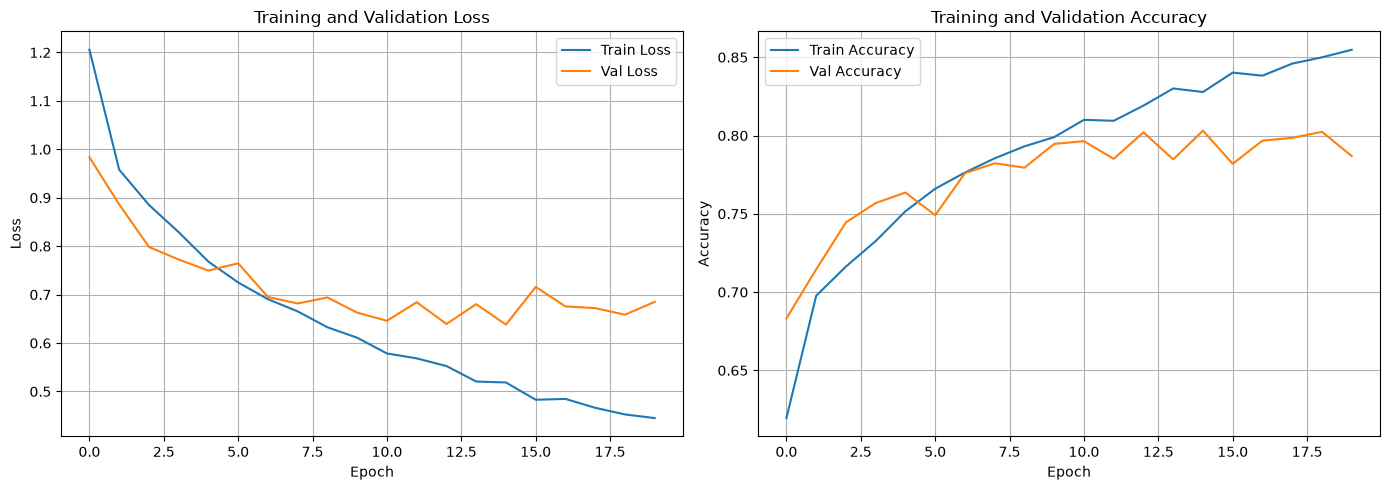


Лучшая точность на validation: 0.8031


In [42]:
import numpy as np
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import SimpleRNN, Dense, Dropout
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# 1. Разделение данных на train/validation/test
# Сначала выделяем test set (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, 
    test_size=0.15, 
    random_state=42, 
    stratify=y  # сохраняем пропорции классов
)

# Затем делим оставшееся на train и validation (примерно 85/15 от исходных)
val_ratio = 0.15 / 0.85  # чтобы получить 15% от общего объема
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=val_ratio,
    random_state=42,
    stratify=y_temp
)

print(f"Размеры выборок:")
print(f"Train: {X_train.shape[0]} записей")
print(f"Validation: {X_val.shape[0]} записей")
print(f"Test: {X_test.shape[0]} записей")

# 2. Преобразование меток в one-hot encoding для категориальной кросс-энтропии
num_classes = len(label_to_idx)
y_train_cat = to_categorical(y_train, num_classes)
y_val_cat = to_categorical(y_val, num_classes)
y_test_cat = to_categorical(y_test, num_classes)

print(f"\nФорма one-hot encoded меток:")
print(f"y_train_cat: {y_train_cat.shape}")
print(f"y_val_cat: {y_val_cat.shape}")
print(f"y_test_cat: {y_test_cat.shape}")

# 3. Построение модели
# Гиперпараметры
n_units = 128  # количество ячеек RNN
m_length = X_train.shape[1]  # длина последовательности
k_dim = X_train.shape[2]  # размерность входного вектора (vocab_size)
activation_rnn = 'tanh'  # функция активации RNN

model = Sequential([
    SimpleRNN(
        units=n_units,
        input_shape=(m_length, k_dim),
        activation=activation_rnn,
        return_sequences=False  # возвращаем только последний выход
    ),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

# Компиляция модели
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Вывод архитектуры
print("\nАрхитектура модели:")
model.summary()

# 4. Обучение модели
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train, y_train_cat,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val_cat),
    callbacks=[early_stopping],
    verbose=1
)

# 5. Визуализация процесса обучения
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График loss
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True)

# График accuracy
axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nЛучшая точность на validation: {max(history.history['val_accuracy']):.4f}")


Результаты на тестовой выборке:
Loss: 0.6419
Accuracy: 0.7992
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Classification Report:
              precision    recall  f1-score   support

      Arabic       0.96      0.98      0.97       300
       Czech       0.43      0.04      0.07        78
       Dutch       0.54      0.16      0.24        45
     English       0.64      0.83      0.72       550
      French       0.00      0.00      0.00        41
      German       0.50      0.28      0.36       109
     Italian       0.50      0.44      0.47       106
    Japanese       0.80      0.85      0.83       149
     Russian       0.89      0.92      0.91      1411
     Spanish       0.19      0.11      0.14        45

    accuracy                           0.80      2834
   macro avg       0.55      0.46      0.47      2834
weighted avg       0.77      0.80      0.78      2834



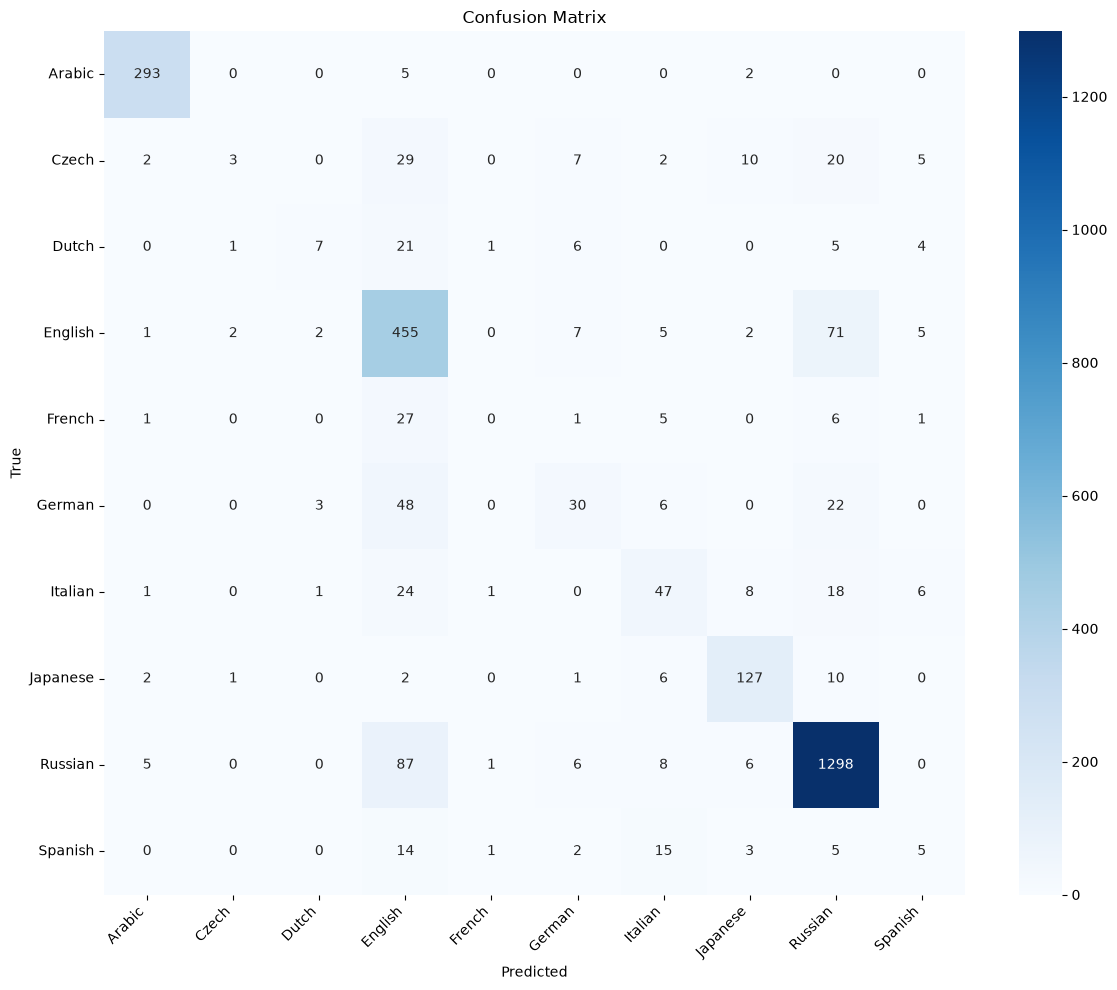

In [45]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 6. Оценка на тестовой выборке
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"\nРезультаты на тестовой выборке:")
print(f"Loss: {test_loss:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")

# Предсказания
y_pred_proba = model.predict(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)

# Classification report
nationality_names = [idx_to_label[i] for i in range(num_classes)]
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=nationality_names))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=nationality_names,
    yticklabels=nationality_names
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [46]:
def predict_nationality(surname_input, model=model, char_to_idx=char_to_idx, 
                       idx_to_label=idx_to_label, max_len=m, vocab_size=vocab_size):
    """
    Предсказание национальности по фамилии
    
    Args:
        surname_input: фамилия на кириллице (строка)
    
    Returns:
        dict с национальностями и их вероятностями
    """
    # Предобработка
    surname = surname_input.strip().lower()
    
    # Кодирование
    encoded = encode_surname_ohe(surname, max_len, char_to_idx, vocab_size)
    encoded_expanded = np.expand_dims(encoded, axis=0)  # добавляем batch dimension
    
    # Предсказание
    probabilities = model.predict(encoded_expanded, verbose=0)[0]
    
    # Сортировка по убыванию вероятности
    sorted_indices = np.argsort(probabilities)[::-1]
    
    result = {}
    for idx in sorted_indices:
        nationality = idx_to_label[idx]
        prob = probabilities[idx]
        result[nationality] = float(prob)
    
    return result

# Тестирование функции
test_surnames = ["иванов", "петров", "смит", "кимура", "мюллер"]
print("\nТестирование предсказаний:")
for surname in test_surnames:
    predictions = predict_nationality(surname)
    top_3 = list(predictions.items())[:3]
    print(f"\n{surname.upper()}:")
    for nat, prob in top_3:
        print(f"  {nat}: {prob:.2%}")


Тестирование предсказаний:

ИВАНОВ:
  Russian: 99.78%
  English: 0.15%
  Czech: 0.06%

ПЕТРОВ:
  English: 67.93%
  Russian: 24.87%
  German: 2.49%

СМИТ:
  German: 33.04%
  English: 31.64%
  Dutch: 24.07%

КИМУРА:
  Japanese: 97.01%
  Italian: 1.78%
  Czech: 0.41%

МЮЛЛЕР:
  English: 68.50%
  Russian: 28.00%
  Czech: 1.77%
